# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

**Data note:** this is the Salary dataset (`YearsExperience` and `Salary`, 30 rows) provided for the course. The cell below saves it as `Salary_Data.csv` so the notebook can load it.

In [1]:
import pandas as pd

data = {
    'YearsExperience': [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
                        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
                        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5],
    'Salary': [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189,
               63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940,
               91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
}
pd.DataFrame(data).to_csv('Salary_Data.csv', index=False)
print('Salary_Data.csv created')

Salary_Data.csv created


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [3]:
df = pd.read_csv("Salary_Data.csv") # e.g., "Salary_Data.csv"
df.head() 



,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [4]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

df.describe()

Shape: (30, 2)

Columns: ['YearsExperience', 'Salary']

Missing values:
 YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


**Extra exploration chart:** the distribution of salaries.

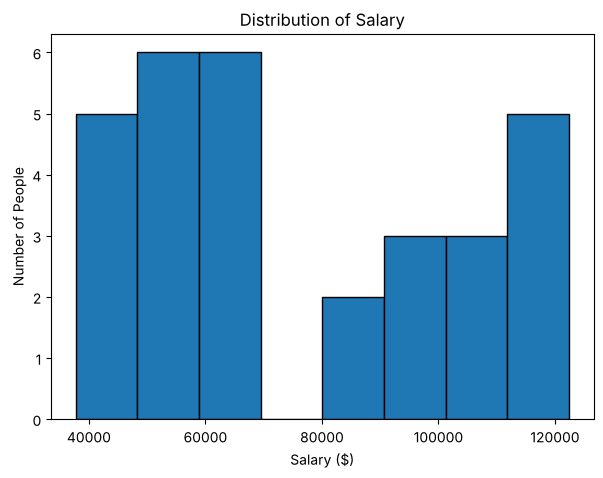

In [5]:
plt.figure(figsize=(7, 5))
plt.hist(df["Salary"], bins=8, edgecolor="black")
plt.title("Distribution of Salary")
plt.xlabel("Salary ($)")
plt.ylabel("Number of People")
plt.show()

## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [6]:
X = df[[ "YearsExperience" ]]     # YearsExperience
y = df["Salary"]           # Salary

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (24, 1) X_test: (6, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 25321.583011776813
Coefficient: 9423.815323030976


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [9]:
y_pred = model.predict(X_test)

pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "ActualSalary": y_test.values,
    "PredictedSalary": y_pred
}).head()

,YearsExperience,ActualSalary,PredictedSalary
0,9.6,112635,115790.210113
1,4.9,67938,71498.278095
2,8.2,113812,102596.868661
3,5.3,83088,75267.804224
4,3.2,64445,55477.792045


## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 6286.453830757749
MSE : 49830096.85590839
RMSE: 7059.04362190151
R^2 : 0.9024461774180497


**Interpretation of the metrics**
- **MAE ≈ $6,286:** on average, the predicted salary is off by about $6,300.
- **MSE ≈ 49.8 million:** the average squared error. It is large because the errors are squared, so it is hard to read in dollars.
- **RMSE ≈ $7,059:** a typical prediction error, back in dollars. Compared with salaries of $38,000 to $122,000, this is a fairly small error.
- **R² ≈ 0.90:** years of experience explain about 90% of the differences in salary, so the model fits well.

# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

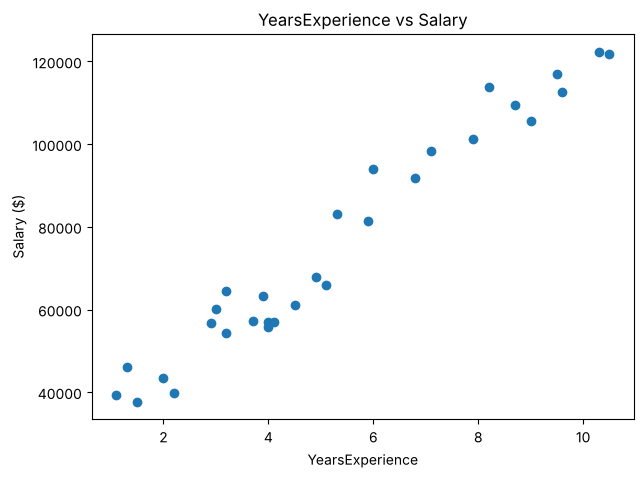

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df["YearsExperience"], df["Salary"])
plt.title("YearsExperience vs Salary")
plt.xlabel("YearsExperience")
plt.ylabel("Salary ($)")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

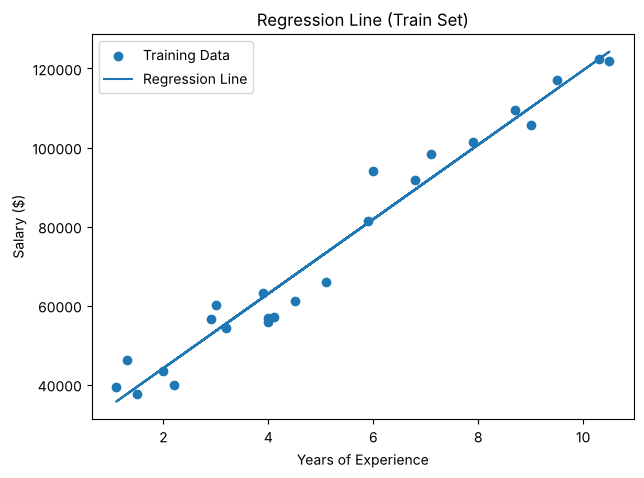

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(X_train["YearsExperience"], y_train, label="Training Data")

y_train_line = model.predict(X_train)
plt.plot(X_train["YearsExperience"], y_train_line, label="Regression Line")

plt.title("Regression Line (Train Set)")
plt.xlabel("Years of Experience")
plt.ylabel("Salary ($)")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

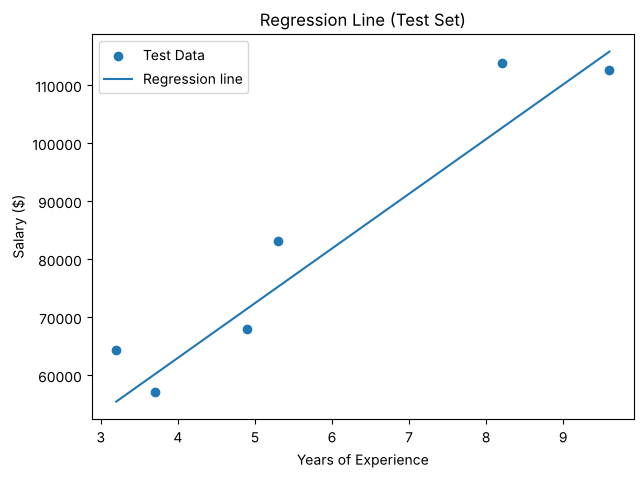

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test["YearsExperience"], y_test, label="Test Data")

X_line = X_test.sort_values(by="YearsExperience")
y_line = model.predict(X_line)

plt.plot(X_line["YearsExperience"], y_line, label="Regression line")

plt.title("Regression Line (Test Set)")
plt.xlabel("Years of Experience")
plt.ylabel("Salary ($)")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

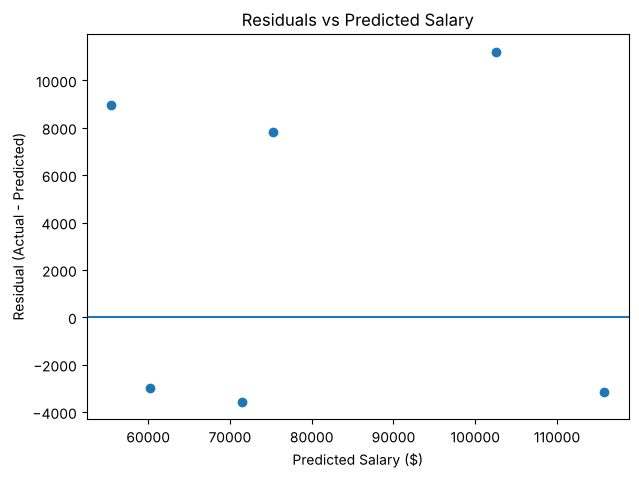

In [14]:
residuals =  y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0)
plt.title("Residuals vs Predicted Salary")
plt.xlabel("Predicted Salary ($)")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [15]:
# Exercise A:
# The slope shows how much the salary changes for each extra year of experience.
# In this model it is about $9,424, so one more year of experience adds roughly $9,400 to the predicted salary.

# Exercise B:
# An R² of about 0.90 means the model explains roughly 90% of the differences in salaries.
# This tells us years of experience is a strong predictor and the line fits the data well.

# Exercise C:
# Outliers are unusual points far from the trend. They pull the regression line toward them,
# which can tilt the line and make the predictions worse for the rest of the data.

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [16]:
# YOUR CODE HERE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("R^2 :", r2_score(y_test, y_pred))

MAE : 5161.328710400183
MSE : 37784662.46621314
R^2 : 0.9414466227178214


**Conclusion (test size 0.2 vs 0.3):**
With a 0.2 test size, MAE was about 6,286 and R² about 0.902. With 0.3, MAE dropped to about 5,161 and R² rose to about 0.941, so the model scored slightly better on this split. Because the dataset has only 30 rows, the scores depend a lot on which rows land in the test set, so the difference does not mean 0.3 is always better. Overall, the model predicts salary well from years of experience.